**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_037_초급_회귀_모바일게임유저관리

### **모바일 게임 유저 관리 — <span style="color:darkgreen">다음 주 플레이 시간(h)</span> 예측 모델 개발**
---

- 도메인 : 모바일 게임 유저 관리
- 목  표 : 유저의 다음 주 플레이 시간(h)을 예측하는 인공지능모델 개발
- 정성소프트의 현업 부서는 유저 데이터를 체계적으로 활용하는 방안을 모색하고 있다.
- 정성소프트의 데이터팀은 축적된 유저 데이터를 활용해 유저의 다음 주 플레이 시간(h)을 예측하는 모델을 만들어 보기로 했다.
- 유저 1,520건 안팎의 이력 데이터를 활용할 수 있다.
- 다음 주 플레이 시간(h)을 미리 알 수 있다면 정성소프트의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 정성소프트의 데이터로 유저의 다음 주 플레이 시간(h)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, quantile, drop, reset_index, copy, fillna, median, sum, isnull, get_dummies, info, sort_values, Series, columns, shape) · NumPy(abs) · seaborn(boxplot, violinplot) · matplotlib(subplots, show) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, LinearRegression, fit, DecisionTreeRegressor, coef_, predict, mean_squared_error) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, evaluate)
- 난이도 : 초급 (설계 난이도 점수 2.55 / 5)
- 예상 소요 시간 : 약 116분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 모바일 게임 유저 관리 (게임·콘텐츠)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- RECORD_ID             : 레코드 식별번호
- PLAY_HOURS            : 주간 플레이 시간(h)
- LEVEL                 : 현재 레벨
- FRIENDS               : 친구 수
- LOGIN_STREAK          : 연속 접속일
- WIN_RATE              : 최근 승률(%)
- SESSION_LEN_MIN       : 평균 세션 길이(분)
- PING_MS               : 평균 지연시간(ms)
- GACHA_SPEND           : 뽑기 지출(만원)
- GENRE                 : 주 장르
- SERVER                : 서버
- ACQUISITION           : 유입 경로
- PLAY_NEXT             : 다음 주 플레이 시간(h)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `pandas`
- 별칭(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pandas'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 6글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pan___ as pd

정답01 = 'pan___'   # 빈칸에 넣은 단어
```

</details>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df 에 할당하고 첫 3개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 읽은 결과를 담을 변수 : df / 경로 없이 파일 이름만으로 읽을 수 있습니다
    - 대상 파일 : data.csv
- **[정답02]** 읽어 온 데이터의 **열(column)의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [4]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
df = pd.read_csv('./data.csv')
df.head(3)
df.shape[1]


13

In [5]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 13

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df 로 열(column)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df = pd.read_csv('./data.csv')
df.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df.shape[__])
```

</details>

### **3. 시각화를 통해 서버(SERVER)와(과) 연속 접속일(LOGIN_STREAK)의 분포와 관계를 파악하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(boxplot, violinplot) · matplotlib(subplots, show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- 서버(SERVER) 별 연속 접속일(LOGIN_STREAK)의 boxplot와 violinplot를 subplots를 활용해 가로 방향으로 나란히 그립니다
- 두 그래프의 제목을 각각 'Count'와 'Right Chart'로 설정합니다
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50500 (\N{HANGUL SYLLABLE A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48513 (\N{HANGUL SYLLABLE BUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local

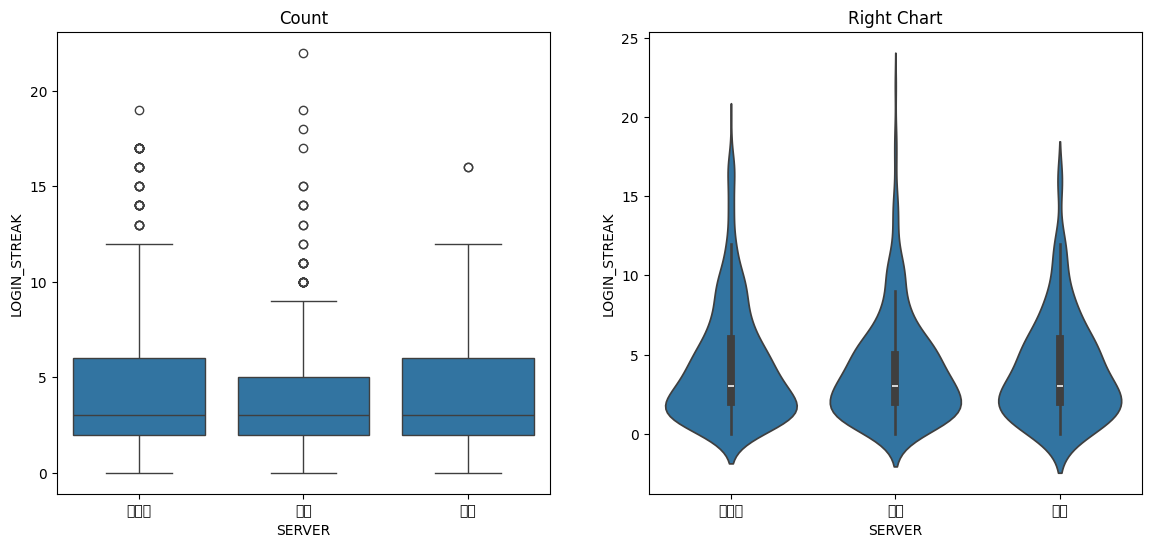

In [6]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

sns.boxplot(data=df, x='SERVER', y='LOGIN_STREAK', ax=axes[0])
sns.violinplot(data=df, x='SERVER', y='LOGIN_STREAK', ax=axes[1])

axes[0].set_title('Count')
axes[1].set_title('Right Chart')

plt.show()

In [7]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'violinplot'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

빈칸의 정답을 먼저 채워 코드 전체를 실행하세요. 분포의 밀도를 바이올린 모양으로 보여주는 seaborn 그래프입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `plt.subplots`, `sns.boxplot`, `sns.violinplot`. 정답은 10글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

sns.boxplot(data=df, x='SERVER', y='LOGIN_STREAK', ax=axes[0])
sns.violi_____(data=df, x='SERVER', y='LOGIN_STREAK', ax=axes[1])

axes[0].set_title('Count')
axes[1].set_title('Right Chart')

plt.show()

정답03 = 'violi_____'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 서버(SERVER) 별 뽑기 지출(만원)(GACHA_SPEND)의 분포를 확인하려 합니다. 제시된 가이드에 맞춰 boxplot으로 시각화하십시오.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(boxplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- seaborn 의 boxplot 으로 뽑기 지출(만원)(GACHA_SPEND) 컬럼의 분포를 그래프로 그리세요
- X축에는 서버(SERVER)를, Y축에는 뽑기 지출(만원)(GACHA_SPEND)를 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50500 (\N{HANGUL SYLLABLE A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48513 (\N{HANGUL SYLLABLE BUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local

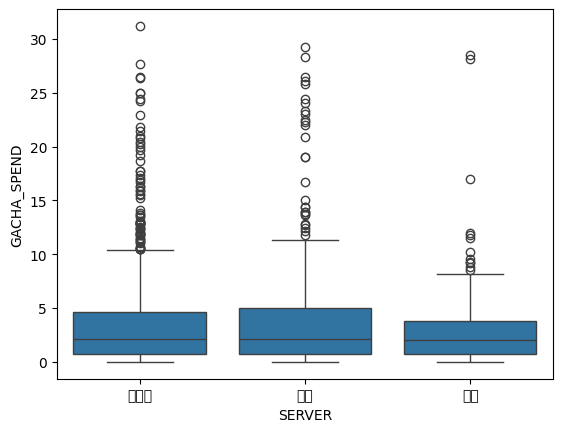

In [8]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.boxplot(data=df, x='SERVER', y='GACHA_SPEND')
plt.show()

In [9]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'boxplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

그룹별 분포와 이상치를 상자 그림으로 보여주는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.boxplot`. 정답은 7글자이고 첫 글자는 `b` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxp___(data=df, x='SERVER', y='GACHA_SPEND')
plt.show()

정답04 = 'boxp___'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 뽑기 지출(만원)(GACHA_SPEND) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 제시된 가이드에 맞춰 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- 뽑기 지출(만원)(GACHA_SPEND)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (IQR 기준 K=1.5)
- AI모델링에 불필요한 레코드 식별번호(RECORD_ID) 컬럼을 삭제하세요
- 전처리를 적용한 데이터프레임은 df_temp 라는 변수명으로 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [11]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

q1 = df['GACHA_SPEND'].quantile(0.25)
q3 = df['GACHA_SPEND'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_temp = df.drop( df[(df['GACHA_SPEND'] > upper_fence) | (df['GACHA_SPEND'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['RECORD_ID'])
df_temp.reset_index(drop=True, inplace=True)

In [12]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'drop'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 행이나 열을 삭제하는 DataFrame 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`. 정답은 4글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df['GACHA_SPEND'].quantile(0.25)
q3 = df['GACHA_SPEND'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_temp = df.dr__( df[(df['GACHA_SPEND'] > upper_fence) | (df['GACHA_SPEND'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['RECORD_ID'])
df_temp.reset_index(drop=True, inplace=True)

정답05 = 'dr__'   # 빈칸에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. 다음 지침에 따라 결측치를 확인하고 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(copy, fillna, median, sum) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 대상 데이터프레임 : df_temp
- 아래 가이드에 따라 결측치를 처리하고 검증하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - 수치형 컬럼(LOGIN_STREAK)의 결측치는 **중앙값** 으로 채우세요
    - 처리가 반영된 데이터프레임은 변수명 df_na 에 저장하고, 남은 결측치 개수를 출력하세요
- **[정답06]** 처리 후 df_na 의 LOGIN_STREAK 평균을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [16]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_na = df_temp.copy()
df_na['LOGIN_STREAK'] = df_na['LOGIN_STREAK'].fillna(df_na['LOGIN_STREAK'].median())
print(df_na.isnull().sum().sum())
round(df_na['LOGIN_STREAK'].mean(),2)

0


np.float64(4.1)

In [17]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 4.1

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치를 중앙값/최빈값으로 채우는 흐름을 점검하세요. 결측치를 채운 뒤 LOGIN_STREAK 의 평균을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `mean`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
df_na = df_temp.copy()
df_na['LOGIN_STREAK'] = df_na['LOGIN_STREAK'].fillna(df_na['LOGIN_STREAK'].median())
print(df_na.isnull().sum().sum())

# [정답06] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(df_na['____'].mean(), __)
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 다음 지침에 따라 범주형 데이터를 변환하는 코드를 정정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_na`
- 다음 지침에 따라 인코딩하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - 대상 데이터프레임 : df_na
    - 문자열(범주형) 컬럼 GENRE, SERVER, ACQUISITION 을(를) get_dummies 로 인코딩하세요 (타깃 PLAY_NEXT 은 제외, drop_first=True)
    - 인코딩된 데이터프레임은 df_enc 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 df_enc 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [21]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_enc = pd.get_dummies(data=df_na, columns=['GENRE', 'SERVER', 'ACQUISITION'], drop_first=True)
df_enc.info()

df_enc.shape[1]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PLAY_HOURS         1416 non-null   float64
 1   LEVEL              1416 non-null   float64
 2   FRIENDS            1416 non-null   float64
 3   LOGIN_STREAK       1416 non-null   float64
 4   WIN_RATE           1416 non-null   float64
 5   SESSION_LEN_MIN    1416 non-null   float64
 6   PING_MS            1416 non-null   float64
 7   GACHA_SPEND        1416 non-null   float64
 8   PLAY_NEXT          1416 non-null   float64
 9   GENRE_액션           1416 non-null   bool   
 10  GENRE_전략           1416 non-null   bool   
 11  GENRE_캐주얼          1416 non-null   bool   
 12  SERVER_아시아         1416 non-null   bool   
 13  SERVER_유럽          1416 non-null   bool   
 14  ACQUISITION_스토어노출  1416 non-null   bool   
 15  ACQUISITION_추천     1416 non-null   bool   
dtypes: bool(7), float64(9)
m

16

In [22]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 16

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_enc = pd.get_dummies(data=df_na, columns=['GENRE', 'SERVER', 'ACQUISITION'], drop_first=True)
df_enc.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_enc.shape[__]
```

</details>

### **8. 학습한 모델을 공정하게 평가하려면 학습에 쓰지 않은 검증 데이터가 필요합니다. 데이터를 훈련용과 검증용으로 나누려 합니다. 제시된 가이드에 맞춰 분리하십시오.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 대상 데이터프레임 : df_enc
- 다음 주 플레이 시간(h)(PLAY_NEXT) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 훈련 75%, 검증 25% 비율로 나누세요 (train_size=0.75) / 반환값을 담을 변수 : X_train(훈련 피처), X_valid(검증 피처), y_train(훈련 레이블), y_valid(검증 레이블)
- random_state 는 42 로 고정하세요
- scikit-learn 의 train_test_split 함수를 활용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [23]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_enc.drop('PLAY_NEXT', axis=1)
y = df_enc['PLAY_NEXT']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.75, random_state=42)

In [24]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_test_split'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 16글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_enc.drop('PLAY_NEXT', axis=1)
y = df_enc['PLAY_NEXT']

X_train, X_valid, y_train, y_valid = train_te________(X, y, train_size=0.75, random_state=42)

정답08 = 'train_te________'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 ss 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [26]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

print(X_valid.max())

5.3572870759575455


In [27]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = 5.36

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 다음 주 플레이 시간(h)(PLAY_NEXT)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, DecisionTreeRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=4, min_samples_leaf=1
    - 난수 시드(random_state) : 42
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [29]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

lin = LinearRegression()
lin.fit(X_train, y_train)

dt = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1, random_state=42)
dt.fit(X_train, y_train)

round(lin.intercept_, 2)

np.float64(9.84)

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [30]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 9.84

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `DecisionTreeRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1, random_state=42)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석하고자 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `lin`
- 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 담으세요
- **[정답11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [34]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
lin = LinearRegression()
lin.fit(X_train, y_train)

coef_s = pd.Series(
    np.abs(lin.coef_),
    index=X.columns
).sort_values(ascending=False)

print(coef_s)


PING_MS              3.742953
PLAY_HOURS           1.481330
FRIENDS              0.509889
SESSION_LEN_MIN      0.286785
SERVER_유럽            0.261662
WIN_RATE             0.250733
LEVEL                0.220793
SERVER_아시아           0.171115
GENRE_액션             0.160256
LOGIN_STREAK         0.068411
GENRE_전략             0.041475
GENRE_캐주얼            0.025772
ACQUISITION_추천       0.013079
GACHA_SPEND          0.011791
ACQUISITION_스토어노출    0.007658
dtype: float64


In [35]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'PING_MS'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, mean_squared_error) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `lin`
- 다음 지침에 따라 각 모델의 MSE(평균제곱오차) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 lin 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 MSE(평균제곱오차) 값을 각각 linreg_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 MSE(평균제곱오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [36]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

linreg_score = mean_squared_error(y_pred_linreg, y_valid)
dt_score = mean_squared_error(y_valid, y_pred_dt)
print(linreg_score, dt_score)

16.047600125135823 22.570805721850515


In [37]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'LinearRegression'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

MSE(평균제곱오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

linreg_score = mean_squared_error(y_valid, y_pred_linreg)
dt_score = mean_squared_error(y_valid, y_pred_dt)
print(linreg_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 다음 주 플레이 시간(h)(PLAY_NEXT)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 조건대로 모델을 만들고 학습시키세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- TensorFlow(Keras) 로 구현하세요
- 은닉층은 Dense 레이어 1개(노드 수 [64]), 활성화 함수는 'relu' 로 하세요
- 첫 은닉층 바로 다음에 Dropout(0.3) 을 추가하세요
- val_loss 가 7 epoch 연속 좋아지지 않으면 멈추는 EarlyStopping(restore_best_weights=True)을 estop 변수에 저장하세요
- 출력층은 노드 1개이고 활성화 함수는 지정하지 않습니다(회귀)
- compile 설정 : optimizer='rmsprop', loss='mse', metrics=[mae]
- batch_size 는 64, epochs 는 20 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블)
- 안내하지 않은 파라미터는 지정하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [41]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=64,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 129.4825 - mae: 9.5958 - val_loss: 117.3096 - val_mae: 9.3431
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 117.8489 - mae: 9.0116 - val_loss: 107.2440 - val_mae: 8.8242
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 108.6633 - mae: 8.5276 - val_loss: 97.7837 - val_mae: 8.3092
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 99.2026 - mae: 8.0149 - val_loss: 88.6470 - val_mae: 7.7855
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 91.4298 - mae: 7.5444 - val_loss: 79.9266 - val_mae: 7.2563
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 82.3368 - mae: 6.9933 - val_loss: 71.4688 - val_mae: 6.7153
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 75.2348 - mae: 6.5277 - val_loss: 63.4010 - val_mae: 6.1687
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 66.9670 - mae: 5.9905 - val_loss: 55.7594 - val_mae: 5.6401
Epoch 9/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - los

In [42]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'patience'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 개선이 없어도 기다려 주는 epoch 수를 지정하는 인자입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 8글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', pati____=7, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=64,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'pati____'   # 빈칸에 넣은 단어
```

</details>

### **14. 학습이 끝난 모델의 최종 성능을 검증 데이터로 한 번 더 확인할 계획입니다.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: TensorFlow(Keras)(evaluate) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 13번 `model`
- 학습된 `model` 의 `evaluate` 로 검증 데이터(X_valid, y_valid)의 성능을 계산하세요 (verbose=0)
    - 반환되는 값은 loss 와 compile 에서 지정한 metrics(mae) 순서입니다. 각각 `loss, mae` 변수에 담으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [43]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

loss, mae = model.evaluate(X_valid, y_valid, verbose=0)

In [44]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'verbose'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

학습된 모델에 검증 데이터를 넣어 손실과 지표를 한 번에 구합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `model.evaluate`. 정답은 7글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
loss, mae = model.evaluate(X_valid, y_valid, verb___=0)

정답14 = 'verb___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.